# FWM tails: repairing gate's errors after the gate

**Purpose.** `fwm_grape.ipynb` tried to repair photon loss with four-wave-mixing (FWM) pumps *during* the d2 X
gate. It found nothing (Stage 2, with six and with 18 teeth). This notebook sets up the other order. The d2 gate
runs as trained. Then a **tail** follows: a stretch of time in which only the two FWM combs act, on the gate's
mixed output state. The result is scored against the *ideal* X gate at the end of the tail.

**The idea in one paragraph.** Comb 1 puts a lost photon back and parks the transmon in $|f\rangle$. Comb 2 moves
that excitation into the readout resonator, which leaks it away (this is where the entropy of the error goes).
Instead of one envelope per tooth, each comb is **one complex waveform** $\eta_c(t)$. It is written in a frame that
turns at the frequency of one reference tooth, the repair $2 \to 3$ (the code's mean photon number is 3). A constant
$\eta_c$ is that one tooth. The other teeth are frequency content of $\eta_c$, about $\pm 2$ MHz per photon away.
The optimizer shapes $\eta_1(t)$ and $\eta_2(t)$ directly.

**Status.** The pipeline is built and tested. **Nothing is trained here.** §2 records, before any training, how much
a tail could gain at best. Short version: at the default length of 3 μs even a perfect tail only about breaks even
with d2 alone. Shorter tails have a little room.

**Decisions** (2026-10-19):

| item | choice |
|---|---|
| input | the mixed output state of the d2 X gate (`pulses/dgrape/u_X_open_d2.npy`) |
| baseline | **d2 alone**, scored at the end of the gate ($F_{\rm pro} = 0.955554$ at $n_c = 16$) |
| controls | the two combs only (comb 1 and comb 2); the cavity drive may be added later |
| strength cap | $\lvert\eta_c(t)\rvert = \lvert\xi_c(t)\rvert \le 0.1$ for each comb |
| readout | readout decay $\kappa_r$ in the model; the readout is **traced out** at the end; $\langle\hat n_r\rangle$ at the end is reported |
| tail length | **3 μs** by default; a parameter. Baselines here also at 0.5, 1 and 2 μs |
| free rotation | **none**: the target is the ideal X. The storage Kerr phase and the tail's own Stark rotation are errors the tail must cancel |

| § | content |
|---|---|
| 1 | the idea: gate, then tail; what a tail can and cannot fix |
| 2 | how much there is to gain: upper limits, which losses are repairable, the cost of the tail's own time, a prediction |
| 3 | one waveform per comb: the definitions, the rotating frame and why it is exact, where the teeth sit |
| 4 | checks of the propagator and the gradient; cost of one evaluation |
| 5 | controls and constraints |
| 6 | the cost function and the baselines at every tail length |
| 7 | the training protocol (not run) |
| 8 | checklist and open decisions |

**Code.** `DGRAPE/fwm_tail.py` (model, propagator, objective, scoring, upper limits),
`validation/test_fwm_tail.py` (10 tests, about ten seconds), `DGRAPE/train_fwm_tail.py` (training; only
`--dry-run` has been used). Nothing in `DGRAPE/fwm.py`, `DGRAPE/model.py` or `DGRAPE/lindblad_np.py` was changed.

**Same model as `fwm_grape.ipynb` and `fwm_tuning.ipynb`.** Same chip (Shirol Table I, `AQEC/device.py`), same drift
with the higher-order terms on, same jump operators (the decay set), same space: storage × transmon (g, e, f) ×
readout. States are written $|n, j, m\rangle$ = (storage photons, transmon level, readout photons). Signs follow
Shirol: $\alpha$ and every $\chi$ are stored positive, with explicit minus signs in the Hamiltonian.

**Words used below.** *Tail*: the time after the gate in which only the combs act. *Tooth*: one frequency of a comb;
tooth $n$ repairs a loss $n{-}1 \to n$. *Process fidelity* $F_{\rm pro}$: the fidelity of the whole channel on the
code, against the ideal gate (DGRAPE's definition). *Pre-image*: the raw optimizer variable before the band filter
and the ramp. *Ideal repair*: an instant, perfect version of what the combs can do, used as an upper limit.

In [1]:
import os
import sys
import time

REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from AQEC import device as dev
from DGRAPE import fwm
from DGRAPE import fwm_tail as ft
import DGRAPE.lindblad_np as lnp
from DGRAPE.code import process_targets, embedded_basis
from DGRAPE.model import Model, operators, index
from core.fourier_cutoff import make_band_mask

# Apple's Accelerate BLAS raises spurious divide/overflow warnings on ordinary complex
# matmuls (no actual NaN/Inf; see core/grape_core.py). Harmless elsewhere.
np.seterr(divide="ignore", over="ignore", invalid="ignore")

TWO_PI = 2 * np.pi
G, E, F = 0, 1, 2
DT = ft.DT                             # us, the 2 ns control grid of d2
N_C = 16                               # training truncation, as in fwm_grape Stage 2
TAIL_LENGTHS = (0.5, 1.0, 2.0, 3.0)    # us; 3 us is the default tail
os.makedirs("figures", exist_ok=True)

OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]


def tidy(ax, grid=True):
    # House style (aqec_experiments.ipynb, fwm_tuning.ipynb): recessive grid, no top/right spines.
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def mhz(w):
    return w / TWO_PI


print(f"d2: {ft.d2_pulse().shape[0]} steps of {DT * 1e3:.0f} ns; default tail {ft.TAIL_US} us = "
      f"{ft.n_steps(ft.TAIL_US)} steps; reference tooth n_ref = {ft.N_REF}")

d2: 550 steps of 2 ns; default tail 3.0 us = 1500 steps; reference tooth n_ref = 3


# 1. The idea

## 1.1 Gate, then tail

$$
|\psi_L\rangle \;\xrightarrow{\ \text{d2 X gate, 1.1 μs}\ }\; \hat\rho(T_g)
\;\xrightarrow{\ \text{tail: combs only, } T_{\rm tail}\ }\; \hat\rho(T_g + T_{\rm tail})
\quad\text{scored against}\quad X|\psi_L\rangle .
$$

The gate is not changed. Its output is a mixed state: mostly the right logical state, plus branches in which a
photon was lost, the transmon decayed, or the gate made a small coherent error. The tail acts on all of them at once.
It has to improve the good branch's partners without hurting the good branch.

## 1.2 Why after the gate

`fwm_grape.ipynb` §6 found two reasons why tones *during* the frozen gate cannot help. Both are gone here.

1. **The Stark shift no longer detunes a gate.** A pump moves the transmon's $g \to e$ line by $2\alpha|\xi|^2$. During
   the gate that line carries d2's photon-number-selective rotations, and the frozen gate cannot follow. In the tail
   there is no gate on that line.
2. **No deadline at the end of the gate.** A repair takes two swaps (comb 1, then comb 2), about 0.3–0.5 μs. During
   the gate, a loss in its last 0.5 μs could not be repaired in time. In the tail the score is taken later.

## 1.3 What a tail can and cannot fix

- **Can:** put a lost photon back (comb 1, $|n{-}1,g\rangle \to |n,f\rangle$) and empty the transmon into the readout
  (comb 2, $|n,f,0\rangle \to |n,g,1\rangle$). A tooth driven slightly off resonance also shifts the phase of one
  photon number. So the combs can, in principle, imprint photon-number-dependent phases too.
- **Cannot:** return a transmon left in $|e\rangle$ (the combs move the transmon by two levels, $g \leftrightarrow f$);
  undo most of d2's coherent error (the combs cannot move amplitude between photon numbers other than by
  adding one photon); remove the $\sqrt5$ distortion a loss leaves on this code (§2.2).

## 1.4 The price

The tail takes time, and the code keeps decaying while it runs: photons are lost at $\bar n\kappa_a = 3\kappa_a
\approx 2.2\,\%$ per μs, and the storage Kerr effect turns the phases of the photon numbers against each other. The
baseline is d2 alone, scored at the end of the gate. So the tail must first earn back its own cost. §2 puts numbers on
both sides.

# 2. How much there is to gain (recorded before any training)

## 2.1 Upper limits at the end of the gate

Two upper limits, both applied *instantly* at the end of the gate (so they ignore the tail's own cost):

- **Ideal FWM repair** (`ft.ideal_repair_kraus`): every state $|n,g\rangle$ with even $n$ (an error state of this
  odd code) becomes $e^{i\phi_n}|n{+}1,g\rangle$; everything else is left alone. One free phase per path, optimized.
  This is the best the two combs could do if they were perfect and instant.
- **Best recovery of any kind** (`ft.optimal_recovery_fidelity`): the best possible quantum channel applied after
  the gate, found numerically (Reimpell–Werner iteration, started from the Petz recovery). It can also undo coherent
  errors and transmon decay, which the combs cannot.

The cell evaluates both for each decay channel alone, as `fwm_grape.ipynb` Table 1 does ($n_c = 16$, readout cut to
one level, which is exact for d2).

In [2]:
B1 = embedded_basis(N_C, 1)
_, T1, W1 = process_targets("X", N_C, 1)
rows = {}
for label, keep in [("closed (no dissipation)", set()), ("storage photon loss only", {"a"}),
                    ("transmon T1 only", {"s_ge", "s_ef"}), ("all decay (training model)", None)]:
    R = ft.d2_output(N_C, 1, keep)
    rep = ft.ideal_repair_fidelity(R, T1, W1, N_C, 1)
    opt = ft.optimal_recovery_fidelity(R, B1)
    rows[label] = {"d2 alone": ft.fidelity_from_outputs(R, T1, W1), "+ ideal FWM repair": rep["F"],
                   "+ best recovery of any kind": opt["F_opt"]}
    if keep == {"a"}:
        PHASES_LOSS = rep["phases"]
    if keep is None:
        rep_135 = ft.ideal_repair_fidelity(R, T1, W1, N_C, 1, starts=(0, 2, 4))
ceil = pd.DataFrame(rows).T
ceil["gain of the ideal repair"] = ceil["+ ideal FWM repair"] - ceil["d2 alone"]
F_D2 = ceil.loc["all decay (training model)", "d2 alone"]
GAIN_IDEAL = ceil.loc["all decay (training model)", "gain of the ideal repair"]
display(ceil.style.format("{:.5f}")
        .set_caption(f"Table 1. Upper limits at the end of the d2 gate (n_c = {N_C}, n_r = 1), "
                     "one decay channel at a time."))
print(f"ideal repair with only the teeth n = 1, 3, 5 (all decay): F = {rep_135['F']:.5f}")

,d2 alone,+ ideal FWM repair,+ best recovery of any kind,gain of the ideal repair
closed (no dissipation),0.99107,0.99158,1.00000,0.00051
storage photon loss only,0.96711,0.97633,0.99755,0.00922
transmon T1 only,0.97922,0.98019,0.99395,0.00098
all decay (training model),0.95555,0.96519,0.98968,0.00964


ideal repair with only the teeth n = 1, 3, 5 (all decay): F = 0.96519


**Reading Table 1.**

- **The ideal FWM repair is worth about +1 %** with every decay channel on: 0.9556 → 0.9652. Most of it comes from
  photon loss (+0.92 % of the 2.4 % photon-loss cost).
- **Only the teeth $n = 1, 3, 5$ matter.** Restricting the ideal repair to the error states $n = 0, 2, 4$ gives the
  same number. By the end of the gate the state is back below 6 photons.
- **A recovery of any kind could reach 0.990.** The gap to 0.965 is what the combs cannot do: undo d2's coherent
  error (the closed row goes to 1) and transmon decay.

## 2.2 Which losses are repairable

A photon lost early in the gate is followed by the rest of the gate, which was never trained on the error states. So
the error branch ends somewhere a simple photon-add cannot fix. `ft.loss_time_profile` follows each first-order loss
branch, $\hat K_t = \sqrt{\kappa_a\,dt}\;\hat U(T_g, t)\,\hat a\,\hat U(t, 0)$ (with $\hat U$ the no-jump evolution),
and scores it with and without the ideal repair (phases from the photon-loss row of Table 1).

loss time (us),share of losses,F after ideal repair,F without repair
0.0-0.2,17.4%,0.102,0.086
0.2-0.4,18.2%,0.190,0.112
0.4-0.6,19.1%,0.389,0.178
0.6-0.8,18.3%,0.624,0.126
0.8-0.9,9.4%,0.774,0.158
0.9-1.0,8.8%,0.799,0.100
1.0-1.1,8.7%,0.873,0.079


expected photon losses per gate (first order): 0.0268
average over all losses: F after ideal repair 0.461, without 0.123
kitten limit (a loss right after a perfect gate, best ideal repair): 0.9353
if every loss were as repairable as those in the last 0.1 us (0.873): gain 0.0201 instead of 0.0090


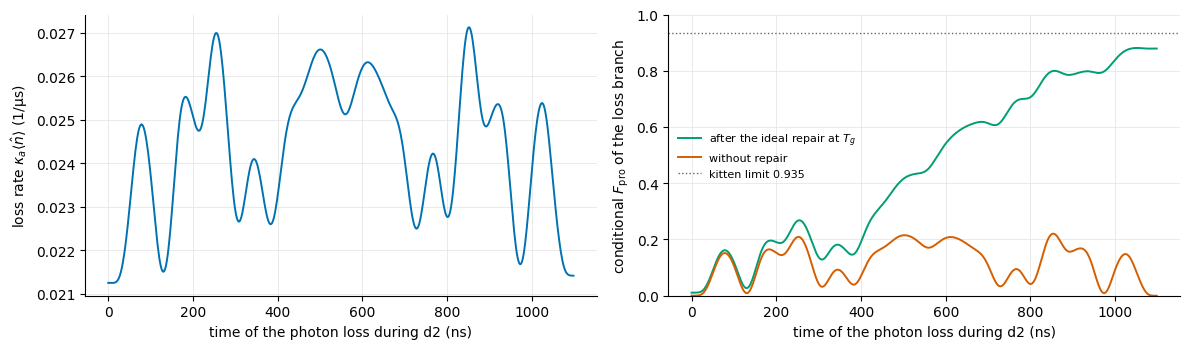

In [3]:
prof = ft.loss_time_profile(PHASES_LOSS, N_C)
tot = prof["p"].sum()
edges = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0, 1.1]
rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (prof["t"] >= lo - 1e-9) & (prof["t"] < hi - 1e-9)
    pw = prof["p"][sel]
    rows.append({"loss time (us)": f"{lo:.1f}-{hi:.1f}", "share of losses": pw.sum() / tot,
                 "F after ideal repair": np.sum(pw * prof["f_repaired"][sel]) / pw.sum(),
                 "F without repair": np.sum(pw * prof["f_unrepaired"][sel]) / pw.sum()})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"share of losses": "{:.1%}", "F after ideal repair": "{:.3f}", "F without repair": "{:.3f}"})
        .set_caption("Table 2. Photon losses during d2, by when they happen: the share of all losses, and the "
                     "conditional process fidelity of that branch with and without the ideal repair at T_g."))
f_rep_mean = np.sum(prof["p"] * prof["f_repaired"]) / tot
f_none_mean = np.sum(prof["p"] * prof["f_unrepaired"]) / tot
late = prof["t"] >= 1.0
f_late = np.sum(prof["p"][late] * prof["f_repaired"][late]) / prof["p"][late].sum()
print(f"expected photon losses per gate (first order): {tot:.4f}")
print(f"average over all losses: F after ideal repair {f_rep_mean:.3f}, without {f_none_mean:.3f}")
print(f"kitten limit (a loss right after a perfect gate, best ideal repair): {ft.kitten_repair_limit():.4f}")
print(f"if every loss were as repairable as those in the last 0.1 us ({f_late:.3f}): gain "
      f"{tot * (f_late - f_none_mean):.4f} instead of {tot * (f_rep_mean - f_none_mean):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
t_ns = prof["t"] * 1e3
axes[0].plot(t_ns, prof["p"] / DT, color=OKABE[0], lw=1.4)
axes[0].set_ylabel(r"loss rate $\kappa_a\langle\hat n\rangle$ (1/μs)")
axes[1].plot(t_ns, prof["f_repaired"], color=OKABE[2], lw=1.4, label="after the ideal repair at $T_g$")
axes[1].plot(t_ns, prof["f_unrepaired"], color=OKABE[4], lw=1.4, label="without repair")
axes[1].axhline(ft.kitten_repair_limit(), color="0.4", ls=":", lw=1, label="kitten limit 0.935")
axes[1].set_ylabel("conditional $F_{\\rm pro}$ of the loss branch")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8, frameon=False, loc="center left")
for ax in axes:
    ax.set_xlabel("time of the photon loss during d2 (ns)")
    tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_loss_timing.png", dpi=150)
plt.show()

**Table 2 and Figure 1.** (a) When the photon losses happen during d2. (b) How well each loss branch scores at the
end of the gate, with and without the ideal repair.

- **Late losses are repairable, early ones are not.** A loss in the last 0.1 μs is repaired to about 0.87. A loss
  in the first 0.4 μs only to 0.10–0.19: the rest of the gate scrambles it.
- **On average a repaired loss scores 0.46**, against 0.12 without repair. That is the +0.92 % of Table 1.
- **Two limits stack.** Even a loss right after a perfect gate repairs only to 0.935 (the *kitten limit*). A loss
  turns $(|1\rangle + |5\rangle)/\sqrt2$ into $(|0\rangle + \sqrt5|4\rangle)/\sqrt6$; adding the photon back gives
  $(|1\rangle + \sqrt5|5\rangle)/\sqrt6$, not the code word. No comb waveform can change the $1:\sqrt5$ ratio.
- **The bigger lever is the gate.** If d2 were trained so that every loss looked like a late one, the same ideal
  repair would gain about twice as much (printed above). That is a later step (§8).

## 2.3 The cost of the tail's own time

With no tones at all, d2 followed by an idle tail. The cell splits the cost: closed system (only the Kerr and
$\chi'$ phases act), photon loss only, and every decay channel with the Kerr and $\chi'$ terms switched off *in the
tail*.

In [4]:
T2, W2 = ft.tail_targets(N_C, 2)
idle_rows = {}
for label, keep, hot in [("all decay", None, True), ("closed (Kerr and chi' only)", set(), True),
                         ("photon loss only", {"a"}, True),
                         ("all decay, Kerr and chi' off in the tail", None, False)]:
    tm = ft.tail_model(N_C, 2, include_higher_order=hot, keep=keep)
    R = ft.d2_output(N_C, 2, keep)
    row = {"0 (d2 alone)": ft.fidelity_from_outputs(R, T2, W2)}
    n_prev = 0
    for T in TAIL_LENGTHS:                      # eta = 0 is time independent: chain the segments
        n = ft.n_steps(T)
        R, _ = ft.propagate(tm, np.zeros((n - n_prev, 2)), R)
        n_prev = n
        row[f"{T:g} us"] = ft.fidelity_from_outputs(R, T2, W2)
    idle_rows[label] = row
idle = pd.DataFrame(idle_rows).T
display(idle.style.format("{:.5f}")
        .set_caption(f"Table 3. d2 followed by an idle tail (no tones), n_c = {N_C}, n_r = 2."))
KERR_PHASE = {n: -(dev.K_a / 2) * n * (n - 1) for n in (1, 3, 5)}       # rad/us, transmon in g
print("Kerr phase per us on |1>, |3>, |5> (rad):", {n: round(v, 4) for n, v in KERR_PHASE.items()})
print(f"relative phase |5> vs |1> after 3 us: {abs(KERR_PHASE[5] - KERR_PHASE[1]) * 3:.3f} rad")

,0 (d2 alone),0.5 us,1 us,2 us,3 us
all decay,0.95555,0.94363,0.92917,0.89318,0.84879
closed (Kerr and chi' only),0.99107,0.98960,0.98525,0.96808,0.94005
photon loss only,0.96711,0.95503,0.94038,0.90394,0.85898
"all decay, Kerr and chi' off in the tail",0.95555,0.94507,0.93471,0.91438,0.89453


Kerr phase per us on |1>, |3>, |5> (rad): {1: -0.0, 3: -0.0622, 5: -0.2073}
relative phase |5> vs |1> after 3 us: 0.622 rad


**Reading Table 3.**

- **Waiting 3 μs costs 10.7 %**: d2 alone 0.9556, d2 + 3 μs idle 0.8488.
- **About half of that is the storage Kerr effect, not loss.** With no dissipation at all, 3 μs cost 5.1 % (closed
  row). Kerr turns $|5\rangle$ against $|1\rangle$ by 0.62 rad in 3 μs, which distorts $|0_L\rangle$. With no free
  rotation allowed, the tail has to cancel this phase itself; off-resonant teeth can shift single photon numbers.
- **Every decay channel together costs 6.1 % over 3 μs** once Kerr and $\chi'$ are off in the tail
  (0.9556 → 0.8945). With the Kerr phase on as well, the two costs add up to the 10.7 %.

## 2.4 Prediction, recorded before training

A rough upper estimate for an optimized tail of length $T$, against d2 alone:

$$
\Delta F \lesssim \underbrace{G}_{\text{d2's losses repaired}}
- \underbrace{\bar n\kappa_a\,\min(T, \tau)}_{\text{losses too late to repair}}
- \underbrace{\bar n\kappa_a\,(T - \tau)_+\,(1 - 0.935)}_{\text{repaired losses, kitten limit}},
$$

with $G$ = the ideal-repair gain of Table 1, $\bar n = 3$, and $\tau \approx 0.3$ μs the shortest time a repair can
take. (Telling even from odd photon numbers takes about $\pi/\chi_{gf} = 0.24$ μs, plus a comb-2 swap.) It is
**optimistic**: it assumes the Kerr phase is cancelled exactly, repairs are perfect once started, and ignores
transmon decay during repairs, dephasing, and losses during a repair.

In [5]:
TAU_REPAIR = 0.3                     # us
rate = 3 * dev.kappa_a               # photon losses per us at nbar = 3
f_k = ft.kitten_repair_limit()
rows = []
for T in TAIL_LENGTHS:
    gain = GAIN_IDEAL if T >= TAU_REPAIR else 0.0
    late = rate * min(T, TAU_REPAIR)
    rep = rate * max(T - TAU_REPAIR, 0.0) * (1 - f_k)
    rows.append({"tail (us)": T, "d2's losses repaired": gain, "losses too late": -late,
                 "repaired losses (kitten limit)": -rep, "upper estimate vs d2 alone": gain - late - rep})
cols = [k for k in rows[0] if k != "tail (us)"]
display(pd.DataFrame(rows).style.hide(axis="index").format({**{c: "{:+.4f}" for c in cols}, "tail (us)": "{:g}"})
        .set_caption("Table 4. Optimistic upper estimate of what an optimized tail can gain over d2 alone."))

tail (us),d2's losses repaired,losses too late,repaired losses (kitten limit),upper estimate vs d2 alone
0.5,+0.0096,-0.0066,-0.0003,+0.0027
1,+0.0096,-0.0066,-0.0010,+0.0020
2,+0.0096,-0.0066,-0.0024,+0.0006
3,+0.0096,-0.0066,-0.0039,-0.0008


**The prediction.**

- **At 3 μs the upper estimate is about −0.1 %: a perfect tail roughly breaks even with d2 alone, and a real one will
  fall below it.** The tail spends 3 μs exposed to loss. Every repaired loss still costs 6.5 % (the kitten limit),
  and losses near the end cannot be repaired in time.
- **Shorter tails have a little room**: about +0.3 % at 0.5 μs, +0.2 % at 1 μs. That is near the 0.3 % go threshold of
  `fwm_grape.ipynb`, and only if the tail is close to perfect.
- **Against "d2 + the same idle time" (Table 3), any working tail looks large**, because it also repairs the losses
  and cancels the Kerr phase of its own time. That comparison is reported, but the decision is against d2 alone.

# 3. One waveform per comb

## 3.1 Definitions

- **Pump displacement** $\beta$: the small, dimensionless, complex amplitude by which a strong off-resonant pump
  shakes the transmon. $|\beta|^2$ is roughly the number of pump photons in the transmon. It enters the fourth-order
  expansion of the junction cosine and gives both the FWM couplings and the Stark shifts (`fwm_tuning.ipynb` §1).
- **Tooth** $k = (c, n)$ in `fwm_grape.ipynb`: a slow complex envelope $\beta_{c,n}(t)$ on a fixed carrier
  $\Delta_{c,n}$ (≈ ±140 MHz in the DGRAPE frame). $|\beta_{c,n}|$ is the tooth's strength.
- **Comb displacement** $\xi_c(t) = \sum_n \beta_{c,n}(t)\,e^{i\Delta_{c,n}t}$: everything comb $c$ does at time $t$.
  This is what the Hamiltonian sees: $g_c\xi_c\hat A_c + {\rm h.c.}$ with $\hat A_1 = \hat a^\dagger\hat q^{\dagger 2}$,
  $\hat A_2 = \hat q^2\hat r^\dagger$, and the Stark term $-(|\xi_1|^2 + |\xi_2|^2)\hat S$.
- **The comb waveform** $\eta_c(t)$, this notebook's control: the same comb seen from the reference tooth,

$$
\xi_1(t) = \eta_1(t)\,e^{+i\Delta_{\rm ref}t}, \qquad \xi_2(t) = \eta_2(t)\,e^{-i\Delta_{\rm ref}t},
\qquad \Delta_{\rm ref} = \Delta_{1,3},
$$

with $t$ counted from the start of the tail. $|\eta_c| = |\xi_c|$, so the cap $|\eta_c| \le 0.1$ is `fwm_grape`'s comb
cap. In the lab, comb 1 is one waveform played around the $n = 3$ tooth, $\omega_a + \omega_{gf} - 3\chi_{gf}$, and
comb 2 around $\omega_r - \omega_{gf} + 3\chi_{gf}$.

## 3.2 The rotating frame, and why it is exact

DGRAPE's frame turns every mode at its linear frequency, so $|f\rangle$ sits at $-\alpha$ (the transmon is
nonlinear). The tail adds one more rotation, of $|f\rangle$ only, by $\Delta_{\rm ref} \approx \alpha + 3\chi_{gf}$:
$\hat\rho' = \hat V^\dagger\hat\rho\hat V$ with $\hat V = e^{i\Delta_{\rm ref}t\hat P_f}$. Then

$$
\hat H' = \hat H_d + \Delta_{\rm ref}\hat P_f + \big(\eta_1 g_1\hat A_1 + \eta_2 g_2\hat A_2 + {\rm h.c.}\big)
- \big(|\eta_1|^2 + |\eta_2|^2\big)\hat S \;\big[+\,\eta_1\eta_2\hat M + {\rm h.c.}\big].
$$

- $\hat A_1$ raises $g \to f$ and picks up a phase from $\hat V$ that cancels comb 1's carrier; $\hat A_2$ lowers
  $f \to g$ and the opposite phase cancels comb 2's.
- $\hat H_d$, $\hat S$ and the pump-mixing operator $\hat M = \hat a^\dagger\hat r^\dagger$ do not touch $|f\rangle$
  off the diagonal, so they are unchanged.
- The jump operators $\hat a$, $\hat r$, $|g\rangle\langle e|$ commute with $\hat P_f$. $|e\rangle\langle f|$ only gains
  an overall phase, which the dissipator ignores. So the Lindblad equation keeps its form.
- $\hat V = 1$ at the start of the tail, and every target has the transmon in $|g\rangle$, where $\hat V$ acts as 1.
  So $F_{\rm pro}$ is the same in both frames.

**Consequence.** With $\eta$ held constant over each 2 ns step, the generator is constant over the step, and one
exponential per step is the exact solution. `fwm_grape` needed four exponentials per step (CF4, $S = 2$) because its
carriers turned by 1.8 rad per step. This only works because the transmon drive is off in the tail: its
$e \to f$ element would turn at $\Delta_{\rm ref}$. The cavity drive does not touch $|f\rangle$, so adding it later
keeps the frame exact.

## 3.3 Where the teeth sit

In [6]:
off = ft.tooth_offsets(N_C, ft.N_REF, fwm.FULL_PATHS)
band = ft.ETA_BAND
tab = pd.DataFrame({
    "path n": off["paths"],
    "repair": [f"{n - 1} -> {n}" for n in off["paths"]],
    "starts from": ["error state (even n-1)" if n % 2 else "code word (odd n-1)" for n in off["paths"]],
    "comb 1 offset (MHz)": mhz(off["comb1"]),
    "comb 2 offset (MHz)": mhz(off["comb2"]),
})
tab["inside the band"] = [(band[0] < a < band[1]) and (band[0] < b < band[1])
                          for a, b in zip(tab["comb 1 offset (MHz)"], tab["comb 2 offset (MHz)"])]
display(tab.style.hide(axis="index").format({"comb 1 offset (MHz)": "{:+.3f}", "comb 2 offset (MHz)": "{:+.3f}"})
        .set_caption(f"Table 5. Where each tooth sits inside eta_c (n_ref = {ft.N_REF}). Band on eta_c: "
                     f"{band[0]:+g} to {band[1]:+g} MHz."))
tm16 = ft.tail_model(N_C)
print(f"Delta_ref / 2pi = {mhz(tm16.delta_ref):.3f} MHz (alpha/2pi = {mhz(dev.alpha_q):.2f}, "
      f"3 chi_gf/2pi = {3 * mhz(dev.chi_gf):.2f})")
print(f"Stark shift of every comb-1 line at |eta_1| = 0.1: {mhz(4 * dev.alpha_q + dev.chi_ge) * 0.01:.2f} MHz; "
      f"comb-2 lines: {mhz(4 * dev.alpha_q - dev.chi_qr) * 0.01:.2f} MHz")
print(f"drift spread (half width) of the tail model: {mhz(tm16.model.half_width_d):.1f} MHz, "
      f"DGRAPE frame: {mhz(Model(N_C, 2, include_higher_order=True).half_width_d):.1f} MHz")

path n,repair,starts from,comb 1 offset (MHz),comb 2 offset (MHz),inside the band
1,0 -> 1,error state (even n-1),-4.135,+4.135,True
2,1 -> 2,code word (odd n-1),-2.066,+2.069,True
3,2 -> 3,error state (even n-1),+0.000,+0.007,True
4,3 -> 4,code word (odd n-1),+2.062,-2.052,True
5,4 -> 5,error state (even n-1),+4.120,-4.107,True
6,5 -> 6,code word (odd n-1),+6.174,-6.158,True
7,6 -> 7,error state (even n-1),+8.225,-8.205,True
8,7 -> 8,code word (odd n-1),+10.271,-10.248,True
9,8 -> 9,error state (even n-1),+12.314,-12.288,False


Delta_ref / 2pi = 140.485 MHz (alpha/2pi = 134.28, 3 chi_gf/2pi = 6.21)
Stark shift of every comb-1 line at |eta_1| = 0.1: 5.38 MHz; comb-2 lines: 5.36 MHz
drift spread (half width) of the tail model: 15.5 MHz, DGRAPE frame: 82.6 MHz


**Reading Table 5.**

- **Each comb is a ladder with one rung per photon**, 2.06 MHz apart. Comb 1 climbs with $n$, comb 2 is its mirror
  image. The repair teeth $n = 1, 3, 5$ sit at about $-4.1$, 0 and $+4.1$ MHz.
- **The teeth that would harm the code are interleaved with the useful ones.** Teeth with even $n$ start from a code
  word ($|1\rangle$, $|3\rangle$, $|5\rangle$) and would pump it out. A band cannot exclude them; the waveform has to
  avoid them (or use them gently, off resonance, to shift phases).
- **The Stark shift moves all teeth of a comb together**, by 5.4 MHz at the cap, the same for every $n$. In the
  one-waveform form, following it is one phase ramp on $\eta_c$. The band, ±12 MHz, leaves room for that.
- The tail's drift spans 15 MHz instead of 83 MHz. That keeps the single exponential per step short (§4.1).

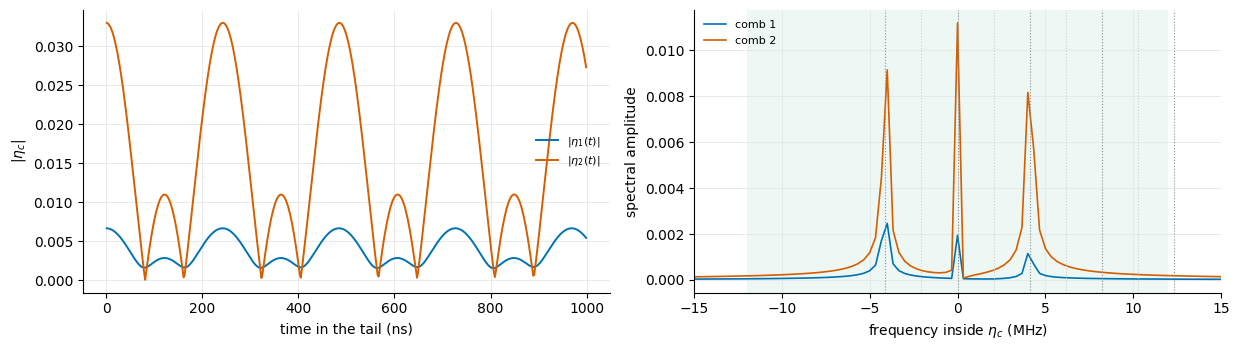

In [7]:
lib = ft.start_library(ft.TAIL_US, n_c=N_C)
eta_t2 = lib["tableII"]
N3 = eta_t2.shape[0]
t_us = (np.arange(N3) + 0.5) * DT
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
show = t_us <= 1.0
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    axes[0].plot(t_us[show] * 1e3, np.abs(eta_t2[show, c]), color=col, lw=1.4, label=fr"$|\eta_{c + 1}(t)|$")
axes[0].set_xlabel("time in the tail (ns)")
axes[0].set_ylabel(r"$|\eta_c|$")
axes[0].legend(fontsize=8, frameon=False)
freq = np.fft.fftshift(np.fft.fftfreq(N3, DT))             # MHz
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    spec = np.abs(np.fft.fftshift(np.fft.fft(eta_t2[:, c]))) / N3
    axes[1].plot(freq, spec, color=col, lw=1.2, label=f"comb {c + 1}")
for n, x1 in zip(off["paths"], mhz(off["comb1"])):
    axes[1].axvline(x1, color="0.8" if n % 2 == 0 else "0.55", lw=0.8, ls=":")
axes[1].axvspan(band[0], band[1], color=OKABE[2], alpha=0.07, lw=0)
axes[1].set_xlim(-15, 15)
axes[1].set_xlabel("frequency inside $\\eta_c$ (MHz)")
axes[1].set_ylabel("spectral amplitude")
axes[1].legend(fontsize=8, frameon=False)
for ax in axes:
    tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_tableII_waveform.png", dpi=150)
plt.show()

**Figure 2. Shirol's Table II teeth written as one waveform per comb.** (a) $|\eta_c(t)|$ over the first μs. (b) The
spectrum over 3 μs; dotted lines mark the comb-1 teeth (darker: repair teeth $n$ odd), green the band.

- **A comb is a pulse train.** Three teeth 4.13 MHz apart beat with a period of 1/(4.13 MHz) = 242 ns. That is also
  $\pi/\chi_{gf}$, the time needed to tell even photon numbers from odd. So a tail cannot be much shorter than about
  0.25 μs, whatever the optimizer finds.
- The comb-2 teeth are the strong ones at Table II ($\beta = 0.011$ each, $|\eta_2|$ up to 0.033).

# 4. Checks

Each check compares the tail propagator with something it does not use itself. `validation/test_fwm_tail.py` runs
smaller versions of all of them.

1. **No tones = DGRAPE's idle evolution.** With $\eta = 0$, the tail (rotated frame) and `lnp.propagate` (DGRAPE frame)
   must give the same $F_{\rm pro}$ and the same transmon-$g$ block.
2. **The frame is exact.** A random piecewise-constant $\eta$, with the Stark and pump-mixing terms on, against
   `fwm.propagate` in the DGRAPE frame with the explicit carriers $(+\Delta_{\rm ref}, -\Delta_{\rm ref})$ and CF4
   sub-steps. CF4 must converge to the tail's single exponential at fourth order.
3. **The gradient.** The W-form gradient against the augmented-generator derivative and central differences.

In [8]:
# Check 1: eta = 0 for 0.5 us at n_c = 16
N05 = ft.n_steps(0.5)
R0 = ft.d2_output(N_C, 2)
R_tail, _ = ft.propagate(tm16, np.zeros((N05, 2)), R0)
R_dg = lnp.propagate(fwm.model_with_channels(N_C, 2, None, True), np.zeros((N05, 4)), R0, DT)
g_idx = (np.arange(tm16.model.d) // 2) % 3 == G
for readout in ("traced", "empty"):
    T_, w_ = ft.tail_targets(N_C, 2, readout=readout)
    print(f"readout {readout:6s}: F tail {ft.fidelity_from_outputs(R_tail, T_, w_):.12f}, "
          f"F DGRAPE {ft.fidelity_from_outputs(R_dg, T_, w_):.12f}")
print(f"largest difference in the transmon-g block: {np.abs(R_tail[:, g_idx][:, :, g_idx] - R_dg[:, g_idx][:, :, g_idx]).max():.1e}")

readout traced: F tail 0.943625106382, F DGRAPE 0.943625106382
readout empty : F tail 0.943625106382, F DGRAPE 0.943625106382
largest difference in the transmon-g block: 2.4e-14


In [9]:
# Check 2: the frame against the DGRAPE frame with explicit carriers, n_c = 10, 0.1 us, strong random eta
n_c10, N_chk = 10, 50
rng = np.random.default_rng(0)
eta_chk = 0.05 * (rng.normal(size=(N_chk, 2)) + 1j * rng.normal(size=(N_chk, 2)))
tm10 = ft.tail_model(n_c10, 2, mixing=1.0)
R0_10 = ft.d2_output(n_c10, 2)
R_f, spec_f = ft.propagate(tm10, eta_chk, R0_10)
m10 = Model(n_c10, 2, include_higher_order=True)
fw10 = fwm.fwm_terms(m10, 1.0, paths=(ft.N_REF,))
fw10.Delta = np.array([tm10.delta_ref, -tm10.delta_ref])
ph = np.exp(1j * tm10.delta_ref * N_chk * DT * np.real(np.diag(operators(n_c10, 2)["Pf"])))
R_f_dg = ph[:, None] * R_f * ph[None, :].conj()            # back to the DGRAPE frame
T10, w10 = ft.tail_targets(n_c10, 2)
rows = []
for S in (2, 4, 8, 16):
    R_d, spec_d = fwm.propagate(m10, fw10, np.zeros((N_chk, 4)), eta_chk, DT, S, R0_10)
    rows.append({"CF4 sub-steps S": S, "max |rho_DGRAPE - rho_tail|": np.abs(R_d - R_f_dg).max(),
                 "F_DGRAPE - F_tail": ft.fidelity_from_outputs(R_d, T10, w10) - ft.fidelity_from_outputs(R_f, T10, w10),
                 "Taylor (s, m) per exponential": str(spec_d)})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"max |rho_DGRAPE - rho_tail|": "{:.1e}", "F_DGRAPE - F_tail": "{:+.1e}"})
        .set_caption(f"Table 6. The tail's single exponential per step (Taylor {spec_f}) against fwm.propagate "
                     f"in the DGRAPE frame (n_c = {n_c10}, 0.1 us, |eta| up to {np.abs(eta_chk).max():.2f}, "
                     "Stark and mixing on)."))

CF4 sub-steps S,max |rho_DGRAPE - rho_tail|,F_DGRAPE - F_tail,"Taylor (s, m) per exponential"
2,5.0e-05,+2.3e-05,"(1, 15)"
4,3.2e-06,+1.4e-06,"(1, 12)"
8,2.0e-07,+9.0e-08,"(1, 10)"
16,1.2e-08,+5.6e-09,"(1, 8)"


In [10]:
# Check 3: the exact gradient, n_c = 8, 20 steps
tm8 = ft.tail_model(8, 2, mixing=1.0)
R0_8 = ft.d2_output(8, 2)
T8, w8 = ft.tail_targets(8, 2)
rng = np.random.default_rng(1)
eta8 = 0.05 * (rng.normal(size=(20, 2)) + 1j * rng.normal(size=(20, 2)))
deta = rng.normal(size=(20, 2)) + 1j * rng.normal(size=(20, 2))
F8, g8 = ft.fidelity_and_grad(tm8, eta8, R0_8, T8, w8)
w_form = np.sum(g8 * fwm.real_from_beta(deta))
aug = ft.directional_derivative(tm8, eta8, R0_8, T8, w8, deta)
h = 1e-6
fd = (ft.fidelity(tm8, eta8 + h * deta, R0_8, T8, w8) - ft.fidelity(tm8, eta8 - h * deta, R0_8, T8, w8)) / (2 * h)
print(f"W form {w_form:+.15f}\naugmented {aug:+.15f}   (relative difference {abs(w_form - aug) / abs(aug):.1e})\n"
      f"central differences {fd:+.12f}   (relative difference {abs(w_form - fd) / abs(fd):.1e})")

W form -0.035802026860084
augmented -0.035802026860084   (relative difference 5.8e-16)
central differences -0.035802026899   (relative difference 1.1e-09)


**Reading the checks.**

- **Check 1:** with no tones the tail and DGRAPE agree to round-off, in both readout conventions.
- **Check 2 (Table 6):** CF4 in the DGRAPE frame converges to the tail's answer, 16 times closer per doubling of
  $S$, the fourth-order rate. So the single exponential per step is the exact solution of the same equation.
- **Check 3:** the W-form gradient equals the augmented-generator derivative to round-off ($6\times10^{-16}$
  relative), and central differences to $10^{-9}$.

## 4.1 Cost of one evaluation

One evaluation of the training cost (fidelity and exact gradient, three process inputs as three parallel jobs) at
$n_c = 16$, for the 3 μs tail. Nothing is optimized.

In [11]:
obj = ft.TailObjective(tail_us=ft.TAIL_US, n_c=N_C, n_jobs=3)
try:
    x_t2 = ft.eta_preimage(lib["tableII"])
    obj.evaluate(np.zeros_like(x_t2) + 1e-9)                # warm up the workers (model build)
    t0 = time.time()
    cost_t2, g_t2, terms_t2 = obj.evaluate(x_t2)
    t_eval = time.time() - t0
finally:
    obj.close()
spec_tail = fwm.spec_for(tm16.model, tm16.fw, np.zeros((1, 4)), np.full((1, 2), 0.1), DT, 1, "midpoint")
m16 = Model(N_C, 2, include_higher_order=True)
fw16 = fwm.fwm_terms(m16)
spec_cf4 = fwm.spec_for(m16, fw16, np.zeros((1, 4)), np.array([[0.1, 0, 0, 0.1, 0, 0]]), DT, 2, "cf4")
print(f"one evaluation, 3 us tail, n_c = {N_C}, 3 jobs: {t_eval:.1f} s   (F_pro {terms_t2['F_pro']:.5f})")
print(f"Taylor (s, m) at the cap: tail {spec_tail}, one exponential per step; "
      f"fwm_grape CF4 S = 2: {spec_cf4}, four per step")

one evaluation, 3 us tail, n_c = 16, 3 jobs: 11.6 s   (F_pro 0.85184)
Taylor (s, m) at the cap: tail (1, 18), one exponential per step; fwm_grape CF4 S = 2: (1, 15), four per step


**Reading.** One evaluation of a 3 μs tail (1500 steps) takes about 12 s here, against 48–62 s for one 1.1 μs Stage 2
evaluation in `fwm_grape` §7 (measured on another machine). A 300-iteration run is roughly one to two hours. The saving
is in the number of exponentials, not their length: one exponential covers the whole 2 ns step, so its Taylor series
is slightly longer than one CF4 exponential's (18 terms against 15), but there is one per step instead of four
(18 terms per step against 60).

# 5. Controls and constraints

| control | shape | meaning | hard limit | soft limit (penalty) | filtering |
|---|---|---|---|---|---|
| $\eta$ | $(N, 4)$ real: $\eta_1^I, \eta_1^Q, \eta_2^I, \eta_2^Q$ | one complex waveform per comb, $\eta = \eta^I - i\eta^Q$ | box $\lvert x\rvert \le 25$ on the pre-image, $x = 250\,\eta$ | $\sum_{t,c}(\lvert\eta_c(t)\rvert - 0.1)_+^2$; derivative | band ±12 MHz on each $\eta_c$, 48 ns ramp at both ends |

- **One cap does the job of two.** `fwm_grape` capped every tooth and, separately, every comb. Here only the comb
  waveform exists, and $|\eta_c| = |\xi_c|$ is constant over a step, so the cap is checked exactly at every step.
- **The band** is symmetric, so the $I \mp iQ$ sign convention does not matter. It holds the repair teeth
  ($\pm 4.1$ MHz), the Stark shift at the cap (5.4 MHz) and a margin.
- **The ramp** makes the tail start and end at zero drive.
- **Weights** are `fwm_grape`'s: amplitude 5.0, derivative 0.625 (the $u$ recipe times $250^2$). Untuned.
- The chain is `fwm.BetaChain` with two tones, which is exactly one `core.ramp.make_constraint_chain` block.

In [12]:
N_tail = ft.n_steps(ft.TAIL_US)
bins = int(make_band_mask(N_tail, DT, *ft.ETA_BAND).sum())
print(f"3 us tail: N = {N_tail} steps, frequency spacing {1 / ft.TAIL_US:.2f} MHz, the band keeps {bins} bins per comb "
      f"-> {2 * bins * 2} real degrees of freedom")
print("penalty weights:", {k: round(v, 4) for k, v in ft.TAIL_PENALTIES.items()}, f"  scale x = {ft.S_ETA:.0f} eta")

3 us tail: N = 1500 steps, frequency spacing 0.33 MHz, the band keeps 73 bins per comb -> 292 real degrees of freedom
penalty weights: {'amp': 5.0, 'deriv': 0.625, 'forbid': 0.0, 'transmon': 0.0}   scale x = 250 eta


# 6. The cost function and the baselines

$$
C(x) = 1 - F_{\rm pro}\big(\text{d2} + \text{tail}(\eta)\big)
+ \lambda_{a}\sum_{t,c}\big(|\eta_c(t)| - 0.1\big)_+^2
+ \lambda_{d}\sum_{t}|\eta(t + dt) - \eta(t)|^2,
\qquad \eta = \frac{\text{ramp}(\text{band}(x))}{250},
$$

$$
F_{\rm pro} = \frac14\sum_b w_b\,{\rm Re}\,{\rm Tr}\Big[\big(\hat T_b \otimes \mathbb 1_r\big)^\dagger\,
\Phi_{\rm tail}\big(\Phi_{\rm d2}(\hat E_b)\big)\Big], \qquad w = (1, 1, 2).
$$

- $\hat T_b$ is the **ideal X** on the code with the transmon in $|g\rangle$. No free rotation: no storage frame
  update, no virtual Z.
- The readout is **traced out** at the end ($\otimes\mathbb 1_r$): a readout photon still there is the dumped error,
  not a mistake. $\langle\hat n_r\rangle$ at the end is reported for every pulse, and `score` also gives the
  stricter "readout empty" fidelity.
- The input $\Phi_{\rm d2}(\hat E_b)$ is computed once (`ft.d2_output`). Training propagates only the tail.

The baselines at each tail length: d2 alone; d2 + idle tail; d2 + Shirol's Table II teeth held on for the whole tail
(PReSPA as published, written as $\eta$).

In [13]:
base = pd.DataFrame(ft.baselines(TAIL_LENGTHS, N_C))
display(base.style.hide(axis="index").format({"tail_us": "{:g}", "F_pro": "{:.5f}", "change_vs_d2": "{:+.4f}"})
        .set_caption(f"Table 7. Baselines, n_c = {N_C}, readout traced. The decision is against 'd2 alone'."))

case,tail_us,F_pro,change_vs_d2
d2 alone,0,0.95555,+0.0000
d2 + idle,0.5,0.94363,-0.0119
d2 + Table II teeth,0.5,0.94194,-0.0136
d2 + idle,1,0.92917,-0.0264
d2 + Table II teeth,1,0.92545,-0.0301
d2 + idle,2,0.89318,-0.0624
d2 + Table II teeth,2,0.89231,-0.0632
d2 + idle,3,0.84879,-0.1068
d2 + Table II teeth,3,0.85332,-0.1022


In [14]:
chain = ft.eta_chain(N_tail)
rows = []
for name, eta in lib.items():
    eta_c = fwm.beta_from_real(chain.to_physical(ft.eta_preimage(eta)))     # as the optimizer will see it
    r = ft.score(eta_c, n_c=N_C)
    rows.append({"start": name, "F_pro": r["F_pro"], "change vs d2 alone": r["F_pro"] - F_D2,
                 "F (readout empty)": r["F_empty"], "<n_r> end": r["n_r_end"], "P_f end": r["P_f_end"],
                 "max |eta_1|": r["max_eta_1"], "max |eta_2|": r["max_eta_2"]})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"F_pro": "{:.5f}", "change vs d2 alone": "{:+.4f}", "F (readout empty)": "{:.5f}",
                 "<n_r> end": "{:.1e}", "P_f end": "{:.1e}", "max |eta_1|": "{:.3f}", "max |eta_2|": "{:.3f}"})
        .set_caption("Table 8. The candidate training starts (ft.start_library) through the training chain, "
                     "3 us tail, n_c = 16."))

start,F_pro,change vs d2 alone,F (readout empty),end,P_f end,max |eta_1|,max |eta_2|
zero,0.84879,-0.1068,0.84879,0.0e+00,1.3e-08,0.000,0.000
tableII,0.85184,-0.1037,0.85071,2.0e-03,5.7e-03,0.007,0.035
tableII_x3,0.55486,-0.4007,0.55368,2.7e-02,4.3e-02,0.021,0.104
bursts_f0.5,0.69085,-0.2647,0.68560,4.2e-02,1.4e-01,0.051,0.074


**Reading Tables 7 and 8.**

- **Every tail with real time in it scores below d2 alone**, as §2 predicted. The idle tail loses 1.2 % at 0.5 μs
  and 10.7 % at 3 μs.
- **Shirol's Table II teeth beat idling only at 3 μs** (+0.45 %), and lose to it at 0.5–2 μs. Held constant, they
  need about 2.8 μs per correction (`fwm_grape.ipynb` Table 2). In a shorter tail they mostly cost. They also do
  nothing about the Kerr phase.
- **Stronger starts are much worse**: `tableII_x3` loses 40 % and `bursts_f0.5` 26 %. The transmon is left in
  $|f\rangle$ with probability 4 % and 14 % at the end, so population was pumped out and not returned. The most likely
  cause is selectivity: at these strengths a comb-1 tooth also drives its neighbours, which start from the code
  words (Table 5). In the tail, selectivity, not the Stark shift on a frozen gate, is what limits the strength.
- **So the landscape starts low everywhere.** Like Stage 2, the optimizer has to climb from below d2 alone; unlike
  Stage 2, there is no frozen gate whose lines the tones detune.

# 7. Training protocol (not run)

1. **Variables:** the pre-image $x$, $(N, 4)$ with $N = 1500$ for 3 μs. The d2 gate is fixed.
2. **Starts** (`ft.start_library`, Table 8): `tableII` (PReSPA as published), `tableII_x3`, `bursts_f0.5` (comb 1
   then comb 2 every 0.6 μs, half the full-swap amplitude), and `zero` plus noise as the control.
3. **Settings:** $n_c = 16$, $n_r = 2$, decay set, higher-order terms on, readout traced, cap 0.1, band ±12 MHz,
   48 ns ramp, weights of §5, L-BFGS-B with `gtol` $10^{-12}$, 300 iterations, best-vs-final.
4. **Command** (one run; four side by side as in `fwm_grape`):

   ```
   python3 DGRAPE/train_fwm_tail.py --start tableII --tag X_tail_a --max-iter 300
   python3 DGRAPE/train_fwm_tail.py --start tableII --tag X_tail_a --dry-run     # one timed evaluation
   ```

   Results go to `~/fwm_runs` (`eta_<tag>.npy`, `xe_<tag>.npy`, `<tag>.json`); copy them to `pulses/dgrape/`,
   never `pulses/`. `--tail-us` sets the length; Table 4 says to also train 0.5 and 1 μs.
5. **Held-out scoring** (`ft.score`): $n_c$ = 18 and 20 (d2 re-propagated), $n_r = 3$, all channels (dephasing and
   heating in the gate and the tail), couplings $g/\sqrt2$, pump mixing $s$ = 1 and 2, Stark off, $\eta \times 0.9$
   and $1.1$, readout empty; plus $\langle\hat n_r\rangle$, $P_e$, $P_f$ at the end and the tones' maxima.
6. **Go / no-go:** a gain of at least 0.3 % over d2 alone at converged $n_c$; held-out $n_c$ agreeing to
   $10^{-4}$; $\max_t|\eta_c| \le 0.1$ within the penalty's tolerance.

# 8. Checklist and open decisions

| # | check | status |
|---|---|---|
| 1 | The frame is exact: idle = DGRAPE idle; random $\eta$ = DGRAPE frame with CF4 | done (§4, tests `Idle`, `Frame`) |
| 2 | Teeth land on their paths (offsets, a path-1 swap) | done (Table 5, test `Teeth`) |
| 3 | Exact gradient: W form = augmented = central differences | done (§4, test `Gradient`) |
| 4 | Objective: pre-image gradient, cap penalty, 3 jobs = 1 job | done (test `Objective`) |
| 5 | Input = d2 propagated at $n_r = 2$ directly | done (test `Input`) |
| 6 | Upper limits: ideal repair, kitten limit, best recovery | done (§2, test `Ceilings`) |
| 7 | $n_r = 2$ vs 3 | done for modest tones (test `Readout`); trained pulses in held-out scoring |
| 8 | Timing of one evaluation | done (§4.1) |
| 9 | Training | not run |

| decision | options | current choice |
|---|---|---|
| tail length | 0.5 – 3 μs | 3 μs default; §2.4 says shorter tails have more room against d2 alone |
| controls | combs / combs + cavity drive | combs; the cavity drive keeps the frame exact and is the next knob |
| cap | per comb / on $|\eta_1|^2 + |\eta_2|^2$ | 0.1 per comb |
| readout at the end | traced / must be empty | traced; "empty" reported |
| the gate | d2 frozen / a gate trained for repairable losses | d2 frozen. A gate trained against the ideal repair's adjoint targets, $\hat T_b \to \mathcal R^\dagger(\hat T_b)$, would make early losses repairable (§2.2), with no change to DGRAPE's machinery |